In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
_r = pathlib.Path.cwd().resolve()
while not (_r / "config" / "settings.yaml").exists() and _r != _r.parent:
    _r = _r.parent
sys.path.insert(0, str(_r))                      # makes `import src...` work from any folder
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from src.notebook_utils import *
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 40, "display.width", 140)
print("project root:", _r)

project root: /app


# Cybersecurity threat analysis
Synthetic security-event telemetry with embedded attack *campaigns*; an unsupervised Isolation Forest (fit on the first 70% of time, no labels) is evaluated against known attack labels.

In [2]:
ev = load_events(); ev['timestamp'] = pd.to_datetime(ev.timestamp); print(ev.shape); ev.head(3)

(25000, 21)


,event_id,timestamp,event_type,severity,source_country,target_service,blocked,response_time_s,bytes_out,failed_attempts,is_attack,f_failed_attempts,f_log_bytes_out,f_response_time_s,f_severity_num,f_hour,f_risky_source,f_blocked,anomaly_score,flagged,split
0,E0000000,2026-08-11 00:03:57,api_call,low,AE,customer_portal,False,0.6126,269.2,0,0,0,5.599162,0.6126,1,0,0,0,0.552552,False,train
1,E0000001,2026-08-11 00:15:05,api_call,low,US,ledger_db,False,0.1884,4104.0,2,0,2,8.319961,0.1884,1,0,0,0,0.500010,False,train
2,E0000002,2026-08-11 00:15:58,api_call,low,AE,ledger_db,False,0.0839,3141.7,0,0,0,8.052838,0.0839,1,0,0,0,0.462362,False,train


In [3]:
atk = ev[ev.is_attack==1]
summary = atk.groupby('event_type').agg(events=('is_attack','size'), blocked=('blocked','mean'), mean_failed=('failed_attempts','mean'), mean_resp=('response_time_s','mean')).round(3).sort_values('events', ascending=False); summary

,events,blocked,mean_failed,mean_resp
event_type,,,,
credential_stuffing,1462,0.858,15.149,0.452
phishing_click,707,0.704,0.317,0.456
ddos_probe,675,0.911,0.311,0.462
data_exfiltration,644,0.564,0.304,0.439
malware_alert,356,0.775,0.306,0.433
api_abuse,341,0.818,0.340,0.445
brute_force,315,0.949,30.016,0.461


[Text(0.5, 1.0, 'Attack events per hour - campaigns appear as bursts')]

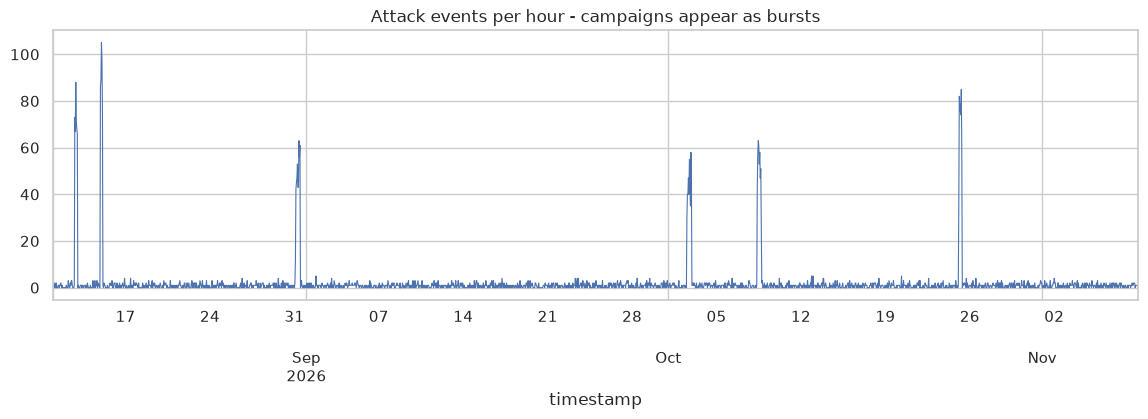

In [4]:
hourly = ev.set_index('timestamp').resample('1h').is_attack.sum()
fig, ax = plt.subplots(figsize=(14, 3.5)); hourly.plot(ax=ax, lw=.8); ax.set(title='Attack events per hour - campaigns appear as bursts')

In [5]:
from sklearn.metrics import roc_auc_score, precision_recall_curve, average_precision_score
print('ROC-AUC', round(roc_auc_score(ev.is_attack, ev.anomaly_score), 3), '| PR-AUC', round(average_precision_score(ev.is_attack, ev.anomaly_score), 3))
print('Flagged:', int(ev.flagged.sum()), '| precision of flags:', round(ev[ev.flagged].is_attack.mean(), 3), '| recall:', round(ev[ev.is_attack==1].flagged.mean(), 3))

ROC-AUC 0.994 | PR-AUC 0.98
Flagged: 3550 | precision of flags: 0.985 | recall: 0.777


Text(0.5, 1.0, 'Share of attacks flagged, by type')

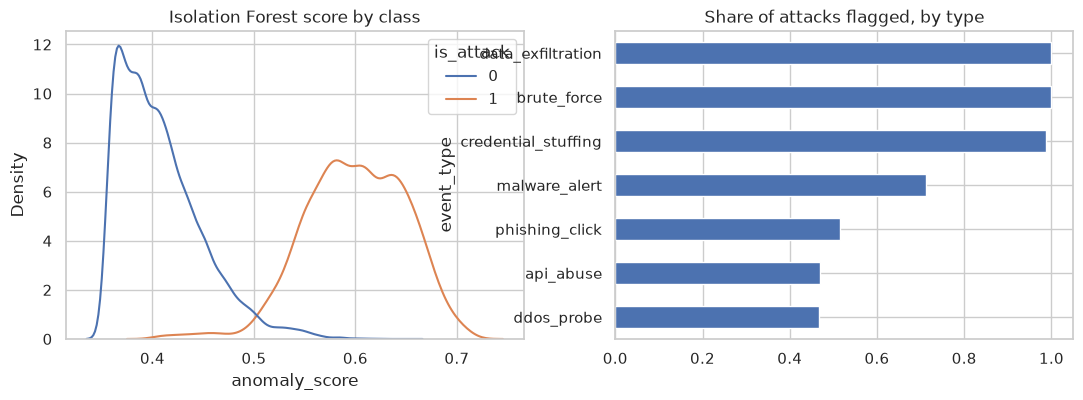

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.kdeplot(data=ev, x='anomaly_score', hue='is_attack', common_norm=False, ax=ax[0]); ax[0].set_title('Isolation Forest score by class')
recall_by_type = atk.groupby('event_type').flagged.mean().sort_values(); recall_by_type.plot.barh(ax=ax[1]); ax[1].set_title('Share of attacks flagged, by type')

In [7]:
pd.crosstab(atk.source_country, atk.event_type)

event_type,api_abuse,brute_force,credential_stuffing,data_exfiltration,ddos_probe,malware_alert,phishing_click
source_country,,,,,,,
AE,26,21,85,34,44,24,35
BR,47,51,221,98,109,60,113
CN,55,46,235,95,83,47,100
DE,24,25,94,55,50,30,56
GB,31,18,81,46,54,20,44
IN,21,20,105,43,50,19,45
NG,48,47,217,101,93,48,94
RU,49,45,222,90,96,48,140
SG,24,18,103,45,46,22,39


**Reading:** high-volume, high-failure attacks (brute force, credential stuffing) are easy for an unsupervised detector; low-footprint attacks (phishing click, API abuse) hide inside benign behaviour - an honest limitation to discuss in the viva.